# Notebook 3: DistilBERT tuning experiments

Compare five DistilBERT configurations (v1 is the default configuration) on the fixed train/validation splits. Training uses training split while all five configurations are evaluated using the validation set. The test split is deliberately not loaded or evaluated here.

Note: Use Google Colab's T4 GPU for faster training time.


## 1. Choose a GPU runtime in Colab

In Colab, select **Runtime → Change runtime type → GPU** if one is available. GPU availability varies. Training can run on CPU, but it will be slower.


In [1]:
%pip -q install transformers==4.50.3 accelerate datasets scikit-learn seaborn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(42)
print('CUDA available:', torch.cuda.is_available())
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')


CUDA available: True
Device: Tesla T4


## 2. Storage and experiment plan

This notebook runs five separate training configurations, each initialized afresh from the same pretrained checkpoint. V1 contains the original settings while V2–V5 make controlled changes. Only validation data is used to compare/select runs. It saves experiment metrics and validation predictions; model weights are saved only once, after the best version is chosen.


In [3]:
from pathlib import Path

# Choose where this notebook reads data and saves/loads models.
STORAGE_MODE = "drive"  # Choose: "drive" for Colab, "local" for Jupyter on your computer

if STORAGE_MODE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/clickbait_project")

elif STORAGE_MODE == "local":
    # Expected layout: project/datasets, project/models, project/results, project/notebooks
    PROJECT_DIR = Path.cwd().resolve()
    if PROJECT_DIR.name.lower() == "notebooks":
        PROJECT_DIR = PROJECT_DIR.parent

    # If needed, set your project folder explicitly, for example:
    # PROJECT_DIR = Path(r"C:\Users\YourName\clickbait-project")

else:
    raise ValueError("STORAGE_MODE must be 'drive' or 'local'.")

DATA_DIR = PROJECT_DIR / "datasets"
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"


TRAIN_PATH = DATA_DIR / "headlines_train.csv"
VALIDATION_PATH = DATA_DIR / "headlines_validation.csv"

DATA_DIR.mkdir(parents=True, exist_ok=True)
required_paths = [TRAIN_PATH, VALIDATION_PATH]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Missing: " + ", ".join(p.name for p in missing_paths))
    print("Upload the missing training/validation CSV files:", ", ".join(p.name for p in missing_paths))
    uploaded_files = files.upload()
    for path in missing_paths:
        if path.name in uploaded_files:
            path.write_bytes(uploaded_files[path.name])
    missing_paths = [path for path in required_paths if not path.exists()]
    if missing_paths:
        raise FileNotFoundError("Still missing: " + ", ".join(p.name for p in missing_paths))

print("Project:", PROJECT_DIR)
print("Train:", TRAIN_PATH)
print("Validation:", VALIDATION_PATH)
print("Dataset folder:", DATA_DIR)

Mounted at /content/drive
Project: /content/drive/MyDrive/clickbait_project
Train: /content/drive/MyDrive/clickbait_project/datasets/headlines_train.csv
Validation: /content/drive/MyDrive/clickbait_project/datasets/headlines_validation.csv
Dataset folder: /content/drive/MyDrive/clickbait_project/datasets


## 3. Load and check the splits

This cell verifies column names and binary labels. It does not combine or reshuffle the files.


In [4]:
def read_split(path, split_name):
    frame = pd.read_csv(path, encoding='utf-8-sig')
    required = {'headline', 'label'}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')
    frame = frame[['headline', 'label']].dropna().copy()
    frame['headline'] = frame['headline'].astype(str).str.strip()
    frame = frame[frame['headline'].ne('')].copy()
    frame['label'] = pd.to_numeric(frame['label'], errors='raise').astype(int)
    if not set(frame['label'].unique()).issubset({0, 1}):
        raise ValueError(f'{path.name} labels must be 0/1; found {sorted(frame["label"].unique())}')
    frame = frame.reset_index(drop=True)
    print(f'{split_name}: {len(frame):,} rows')
    display(frame['label'].value_counts().sort_index().rename_axis('label').to_frame('rows'))
    return frame

train_df = read_split(TRAIN_PATH, 'Training split')
validation_df = read_split(VALIDATION_PATH, 'Validation split')
print('Label mapping: 0 = non-clickbait/news; 1 = clickbait')


Training split: 40,208 rows


,rows
label,
0,24446
1,15762


Validation split: 5,027 rows


,rows
label,
0,3056
1,1971


Label mapping: 0 = non-clickbait/news; 1 = clickbait


## 4. Define five controlled configurations

V1 has the original configurations of 2 epochs and a learning rate of 2e-5. The other versions vary one or two training settings to make a small, practical comparison. The data, seed, base checkpoint, max length, and batch size are kept the same.


In [5]:
BASE_MODEL = 'distilbert/distilbert-base-uncased'
MAX_LENGTH = 64
BATCH_SIZE = 16
SEED = 42

EXPERIMENTS = [
    {"version": "v1", "epochs": 2, "learning_rate": 2e-5, "weight_decay": 0.01},  # existing setup
    {"version": "v2", "epochs": 3, "learning_rate": 2e-5, "weight_decay": 0.01},  # more training
    {"version": "v3", "epochs": 2, "learning_rate": 1e-5, "weight_decay": 0.01},  # smaller updates
    {"version": "v4", "epochs": 2, "learning_rate": 3e-5, "weight_decay": 0.01},  # larger updates
    {"version": "v5", "epochs": 3, "learning_rate": 1e-5, "weight_decay": 0.01},  # combined candidate
]

# Tokenize once; all five runs use exactly the same training and validation rows.
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
def make_hf_dataset(frame):
    raw = Dataset.from_pandas(pd.DataFrame({'text': frame['headline'], 'labels': frame['label']}), preserve_index=False)
    return raw.map(lambda batch: tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH), batched=True, remove_columns=['text'])
train_hf = make_hf_dataset(train_df)
validation_hf = make_hf_dataset(validation_df)
print('Tokenization complete. Five configurations are ready.')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/40208 [00:00<?, ? examples/s]

Map:   0%|          | 0/5027 [00:00<?, ? examples/s]

Tokenization complete. Five configurations are ready.


## 5. Train and evaluate all five versions

Each run starts from the original pretrained checkpoint, not from the previous run. Results are ranked by clickbait F1 (which is the primary metric). Accuracy, precision, and recall are also reported. Validation is for model selection, so do not treat these metrics as final test performance.


Note: Running the cell below takes a long time (around 25 minutes when using Google Colab's T4 GPU as the runtime)





In [15]:
from transformers import TrainerCallback

experiment_rows = []
validation_prediction_frames = {}

for config in EXPERIMENTS:
    version = config["version"]
    print(f"\n=== Training {version}: {config} ===")
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        BASE_MODEL, num_labels=2,
        id2label={0: 'non-clickbait/news', 1: 'clickbait'},
        label2id={'non-clickbait/news': 0, 'clickbait': 1},
    )
    args = TrainingArguments(
        output_dir=f'/content/distilbert_temp_{version}',
        num_train_epochs=config['epochs'],
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=config['learning_rate'],
        weight_decay=config['weight_decay'],
        logging_steps=100, save_strategy='no', report_to='none',
        seed=SEED, fp16=torch.cuda.is_available(),
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_hf,
                      data_collator=data_collator, processing_class=tokenizer)
    trainer.train()
    output = trainer.predict(validation_hf)
    probs = torch.softmax(torch.tensor(output.predictions), dim=1).cpu().numpy()
    y_true = validation_df['label'].to_numpy()
    y_pred = probs.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[1], average='binary', zero_division=0)
    row = {
        'version': version, 'epochs': config['epochs'],
        'learning_rate': config['learning_rate'],
        'accuracy': accuracy_score(y_true, y_pred),
        'clickbait_precision': precision, 'clickbait_recall': recall,
        'clickbait_f1': f1, 'errors': int((y_true != y_pred).sum()),
    }
    experiment_rows.append(row)
    pred_frame = validation_df.copy()
    pred_frame['predicted_label'] = y_pred
    pred_frame['clickbait_confidence_percent'] = (probs[:, 1] * 100).round(2)
    validation_prediction_frames[version] = pred_frame
    print(pd.Series(row).to_string())
    del trainer, model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

results_df = pd.DataFrame(experiment_rows).sort_values('clickbait_f1', ascending=False).reset_index(drop=True)
display(results_df.style.format({'accuracy':'{:.2%}', 'clickbait_precision':'{:.2%}', 'clickbait_recall':'{:.2%}', 'clickbait_f1':'{:.2%}'}))


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== Training v1: {'version': 'v1', 'epochs': 2, 'learning_rate': 2e-05, 'weight_decay': 0.01} ===


Step,Training Loss
100,0.369700
200,0.254600
300,0.247900
400,0.283100
500,0.277700
600,0.235800
700,0.250800
800,0.231900
900,0.229900
1000,0.232000


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


version                      v1
epochs                        2
learning_rate           0.00002
accuracy                0.92043
clickbait_precision    0.908052
clickbait_recall       0.886859
clickbait_f1           0.897331
errors                      400

=== Training v2: {'version': 'v2', 'epochs': 3, 'learning_rate': 2e-05, 'weight_decay': 0.01} ===


Step,Training Loss
100,0.369700
200,0.254500
300,0.248000
400,0.283200
500,0.277900
600,0.236100
700,0.250800
800,0.232800
900,0.230600
1000,0.233300


... (7 outputs left out)

version                      v4
epochs                        2
learning_rate           0.00003
accuracy               0.919435
clickbait_precision    0.901538
clickbait_recall       0.891933
clickbait_f1            0.89671
errors                      405

=== Training v5: {'version': 'v5', 'epochs': 3, 'learning_rate': 1e-05, 'weight_decay': 0.01} ===


Step,Training Loss
100,0.437400
200,0.263500
300,0.249900
400,0.279400
500,0.282200
600,0.239100
700,0.259400
800,0.233000
900,0.231500
1000,0.231900


version                      v5
epochs                        3
learning_rate           0.00001
accuracy               0.919833
clickbait_precision    0.910042
clickbait_recall       0.882801
clickbait_f1           0.896214
errors                      403


,version,epochs,learning_rate,accuracy,clickbait_precision,clickbait_recall,clickbait_f1,errors
0,v3,2,0.000010,92.08%,91.20%,88.33%,89.74%,398
1,v1,2,0.000020,92.04%,90.81%,88.69%,89.73%,400
2,v4,2,0.000030,91.94%,90.15%,89.19%,89.67%,405
3,v5,3,0.000010,91.98%,91.00%,88.28%,89.62%,403
4,v2,3,0.000020,91.47%,89.30%,88.89%,89.09%,429


## 6. Compare validation results and select one version

The same validation set is used to compare all five runs. The version with the highest F1-score is chosen as the definitive version.


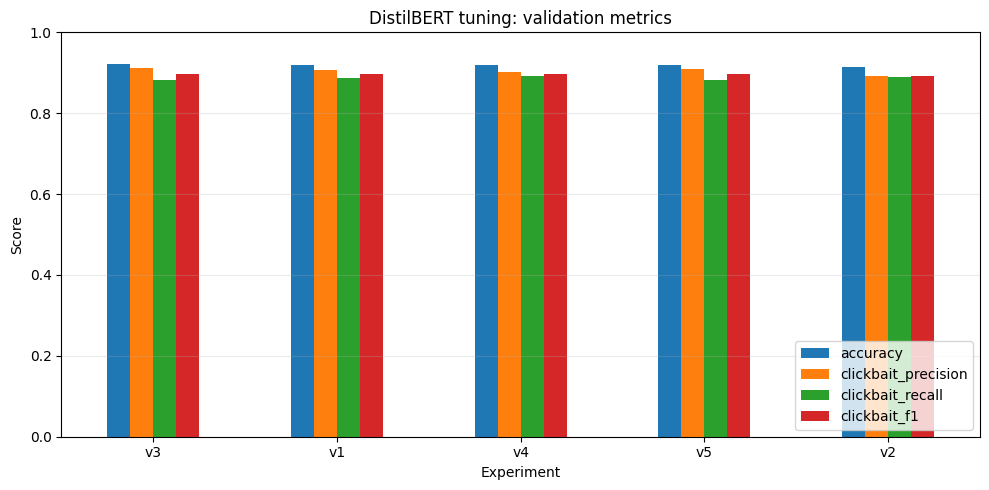


Top validation clickbait F1: v3


In [16]:
# Visual comparison: validation metrics across all five experiments
metric_cols = ['accuracy', 'clickbait_precision', 'clickbait_recall', 'clickbait_f1']
results_df.set_index('version')[metric_cols].plot(kind='bar', figsize=(10, 5), ylim=(0, 1), rot=0)
plt.title('DistilBERT tuning: validation metrics')
plt.ylabel('Score')
plt.xlabel('Experiment')
plt.grid(axis='y', alpha=0.25)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

BEST_VERSION = results_df.iloc[0]['version']
print('\nTop validation clickbait F1:', BEST_VERSION)


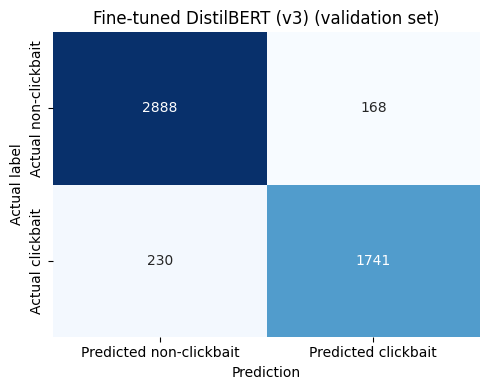

In [17]:
# Show the validation confusion matrix for the version with the highest clickbait F1
best_predictions = validation_prediction_frames[BEST_VERSION]

best_cm = confusion_matrix(
    best_predictions['label'],
    best_predictions['predicted_label'],
    labels=[0, 1]
)

plt.figure(figsize=(5, 4))
sns.heatmap(
    best_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['Predicted non-clickbait', 'Predicted clickbait'],
    yticklabels=['Actual non-clickbait', 'Actual clickbait']
)
plt.title(f'Fine-tuned DistilBERT ({BEST_VERSION}) (validation set)')
plt.xlabel('Prediction')
plt.ylabel('Actual label')
plt.tight_layout()
plt.show()

## 7. Save experiment results and optionally save the selected model
The results table and validation predictions are saved. Set `SAVE_BEST_MODEL = True` only after reviewing the comparison; then the selected configuration is retrained from the base checkpoint and saved once.

In [19]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
results_df.to_csv(RESULTS_DIR / 'distilbert_tuning_validation_metrics.csv', index=False)
for version, frame in validation_prediction_frames.items():
    frame.to_csv(RESULTS_DIR / f'{version}_validation_predictions.csv', index=False, encoding='utf-8-sig')

SAVE_BEST_MODEL = True  # Switch to True after reviewing results and choosing the model.
BEST_MODEL_DIR = MODELS_DIR / f"distilbert_{BEST_VERSION}_new"
if SAVE_BEST_MODEL:
    if BEST_MODEL_DIR.exists():
        raise FileExistsError(f"{BEST_MODEL_DIR} already exists; choose a new destination/version to avoid overwriting.")
    best_config = next(x for x in EXPERIMENTS if x['version'] == BEST_VERSION)
    set_seed(SEED)
    best_model = AutoModelForSequenceClassification.from_pretrained(
        BASE_MODEL, num_labels=2,
        id2label={0: 'non-clickbait/news', 1: 'clickbait'},
        label2id={'non-clickbait/news': 0, 'clickbait': 1},
    )
    best_args = TrainingArguments(
        output_dir=f'/content/distilbert_temp_best_{BEST_VERSION}',
        num_train_epochs=best_config['epochs'],
        per_device_train_batch_size=BATCH_SIZE,
        learning_rate=best_config['learning_rate'],
        weight_decay=best_config['weight_decay'],
        logging_steps=100, save_strategy='no', report_to='none',
        seed=SEED, fp16=torch.cuda.is_available(),
    )
    best_trainer = Trainer(model=best_model, args=best_args, train_dataset=train_hf,
                           data_collator=data_collator, processing_class=tokenizer)
    best_trainer.train()
    BEST_MODEL_DIR.mkdir(parents=True, exist_ok=False)
    best_trainer.save_model(str(BEST_MODEL_DIR))
    tokenizer.save_pretrained(str(BEST_MODEL_DIR))
    print('Saved selected model to:', BEST_MODEL_DIR)
else:
    print('Metrics saved. Best model weights were not saved; review results, then set SAVE_BEST_MODEL=True if desired.')


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
100,0.437600
200,0.263600
300,0.251200
400,0.278800
500,0.282400
600,0.238900
700,0.259600
800,0.232700
900,0.231000
1000,0.231800


Saved selected model to: /content/drive/MyDrive/clickbait_project/models/distilbert_v3_new


## Experiment notes
- Total: five training runs, including V1; each is initialized from the same pretrained DistilBERT checkpoint.
- Training data updates model weights; validation data compares settings.
- Test data is not opened in this tuning notebook. Use it for the final one-time comparison against the unchanged TF–IDF baseline.
- Five runs can take a while; use a Colab GPU if available. If time is tight, stop after V1–V3 and report the actual number of completed experiments.
